# Music Store SQL Case Study

Business questions for a digital music store, answered in SQL (SQLite) on the Chinook database: 59 customers in 24 countries, 412 invoices, 3,503 tracks and 8 employees.

Each query lives in `queries/` as a plain `.sql` file. This notebook runs them in order and adds the interpretation and charts.

SQL features used: multi-table joins, CTEs, `GROUP BY` with `HAVING`-style filters, `CASE`, correlated subqueries, and window functions (`LAG`, `RANK`, `NTILE`, `ROW_NUMBER`, running `SUM`, moving `AVG`).

Note: Chinook is a sample database built for teaching, so its sales are more regular than a real store's. The queries are written to work the same way on real data.

In [1]:
import sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

sns.set_theme(style="whitegrid")
conn = sqlite3.connect("data/chinook.sqlite")

def run(name):
    sql = Path("queries", name).read_text()
    display(Markdown(f"```sql\n{sql.strip()}\n```"))
    return pd.read_sql_query(sql, conn)

## Q1. Where does revenue come from?

In [2]:
q1 = run("01_revenue_by_country.sql"); q1

```sql
-- Q1. Which countries bring in the most revenue, and how much is each customer worth there?
SELECT
    c.Country,
    COUNT(DISTINCT c.CustomerId)                          AS customers,
    ROUND(SUM(i.Total), 2)                                AS revenue,
    ROUND(SUM(i.Total) / COUNT(DISTINCT c.CustomerId), 2) AS revenue_per_customer,
    ROUND(100.0 * SUM(i.Total) / (SELECT SUM(Total) FROM Invoice), 1) AS pct_of_revenue
FROM Customer c
JOIN Invoice  i ON i.CustomerId = c.CustomerId
GROUP BY c.Country
ORDER BY revenue DESC
LIMIT 10;
```

,Country,customers,revenue,revenue_per_customer,pct_of_revenue
0,USA,13,523.06,40.24,22.5
1,Canada,8,303.96,37.99,13.1
2,France,5,195.10,39.02,8.4
3,Brazil,5,190.10,38.02,8.2
4,Germany,4,156.48,39.12,6.7
5,United Kingdom,3,112.86,37.62,4.8
6,Czech Republic,2,90.24,45.12,3.9
7,Portugal,2,77.24,38.62,3.3
8,India,2,75.26,37.63,3.2
9,Chile,1,46.62,46.62,2.0


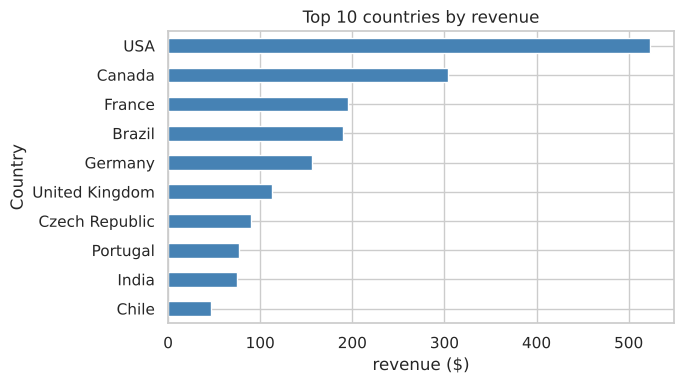

In [3]:
ax = q1.plot.barh(x="Country", y="revenue", legend=False, figsize=(7, 4), color="steelblue")
ax.invert_yaxis(); ax.set_xlabel("revenue ($)"); ax.set_title("Top 10 countries by revenue")
plt.tight_layout(); plt.savefig("images/revenue_by_country.png", dpi=120); plt.show()

The USA and Canada bring in about 36% of revenue, but only because they have the most customers. Revenue per customer is about $38–40 almost everywhere, so growth depends on reaching more customers rather than selling more to each one.

## Q2. Is revenue growing?

In [4]:
q2 = run("02_monthly_revenue_trend.sql"); q2.tail(12)

```sql
-- Q2. Monthly revenue with month-over-month change and a 3-month moving average
WITH monthly AS (
    SELECT strftime('%Y-%m', InvoiceDate) AS month,
           SUM(Total)                     AS revenue
    FROM Invoice
    GROUP BY month
)
SELECT
    month,
    ROUND(revenue, 2) AS revenue,
    ROUND(revenue - LAG(revenue) OVER (ORDER BY month), 2) AS change_vs_prev_month,
    ROUND(AVG(revenue) OVER (ORDER BY month ROWS BETWEEN 2 PRECEDING AND CURRENT ROW), 2) AS moving_avg_3m
FROM monthly
ORDER BY month;
```

,month,revenue,change_vs_prev_month,moving_avg_3m
48,2025-01,37.62,0.00,37.62
49,2025-02,27.72,-9.90,34.32
50,2025-03,37.62,9.90,34.32
51,2025-04,33.66,-3.96,33.00
52,2025-05,37.62,3.96,36.30
53,2025-06,37.62,0.00,36.30
54,2025-07,37.62,0.00,37.62
55,2025-08,37.62,0.00,37.62
56,2025-09,37.62,0.00,37.62
57,2025-10,37.62,0.00,37.62


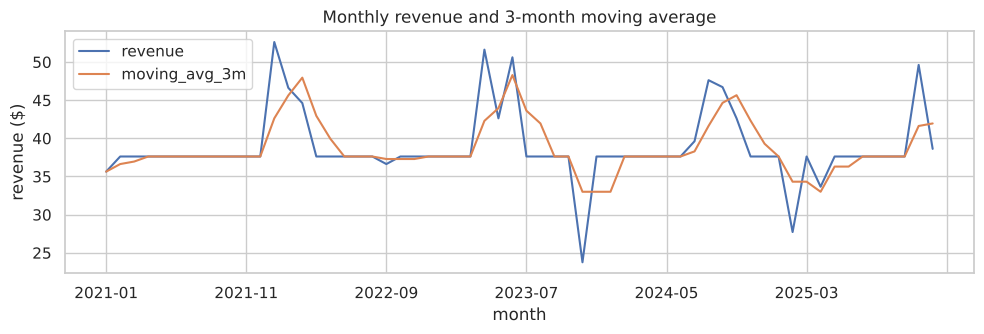

In [5]:
ax = q2.plot(x="month", y=["revenue", "moving_avg_3m"], figsize=(10, 3.5))
ax.set_ylabel("revenue ($)"); ax.set_title("Monthly revenue and 3-month moving average")
plt.tight_layout(); plt.savefig("images/monthly_revenue.png", dpi=120); plt.show()

Revenue is flat at roughly $37–38 a month with occasional spikes. There is no growth trend over five years, which matches the finding above: the customer base is not growing.

## Q3. Which genre wins in each country?

In [6]:
run("03_top_genre_per_country.sql")

```sql
-- Q3. The best-selling genre in each country (ties kept)
WITH genre_sales AS (
    SELECT i.BillingCountry AS country,
           g.Name           AS genre,
           SUM(il.Quantity) AS units
    FROM InvoiceLine il
    JOIN Invoice i ON i.InvoiceId = il.InvoiceId
    JOIN Track   t ON t.TrackId   = il.TrackId
    JOIN Genre   g ON g.GenreId   = t.GenreId
    GROUP BY country, genre
),
ranked AS (
    SELECT *,
           RANK() OVER (PARTITION BY country ORDER BY units DESC) AS rnk,
           ROUND(100.0 * units / SUM(units) OVER (PARTITION BY country), 1) AS pct_of_country_units
    FROM genre_sales
)
SELECT country, genre, units, pct_of_country_units
FROM ranked
WHERE rnk = 1
ORDER BY units DESC;
```

,country,genre,units,pct_of_country_units
0,USA,Rock,157,31.8
1,Canada,Rock,107,35.2
2,Brazil,Rock,81,42.6
3,France,Rock,65,34.2
4,Germany,Rock,62,40.8
5,United Kingdom,Rock,37,32.5
6,Portugal,Rock,31,40.8
7,Czech Republic,Rock,25,32.9
8,India,Rock,25,33.8
9,Australia,Rock,22,57.9


Rock is the top genre in 22 of 24 countries and ties with Alternative & Punk in Argentina. Sweden is the one exception, where Latin leads. In some smaller markets Rock is more than half of all units. Marketing can lead with Rock almost everywhere, with Sweden as a candidate for a Latin-focused campaign.

## Q4. Which customers matter most? (RFM segmentation)

In [7]:
q4 = run("04_customer_rfm_segments.sql"); q4.head(15)

```sql
-- Q4. RFM segmentation: score each customer 1-4 on recency, frequency and monetary value
WITH base AS (
    SELECT c.CustomerId,
           c.FirstName || ' ' || c.LastName AS customer,
           c.Country,
           julianday((SELECT MAX(InvoiceDate) FROM Invoice)) - julianday(MAX(i.InvoiceDate)) AS days_since_last,
           COUNT(i.InvoiceId) AS orders,
           SUM(i.Total)       AS spend
    FROM Customer c
    JOIN Invoice  i ON i.CustomerId = c.CustomerId
    GROUP BY c.CustomerId
),
scored AS (
    SELECT *,
           NTILE(4) OVER (ORDER BY days_since_last DESC) AS r_score,  -- more recent = higher
           NTILE(4) OVER (ORDER BY orders)               AS f_score,
           NTILE(4) OVER (ORDER BY spend)                AS m_score
    FROM base
)
SELECT customer, Country, CAST(days_since_last AS INT) AS days_since_last, orders,
       ROUND(spend, 2) AS spend, r_score, f_score, m_score,
       CASE
           WHEN r_score >= 3 AND m_score = 4 THEN 'Champion'
           WHEN r_score <= 2 AND m_score >= 3 THEN 'At risk (high value, lapsing)'
           WHEN r_score >= 3                  THEN 'Active'
           ELSE 'Low value / lapsing'
       END AS segment
FROM scored
ORDER BY spend DESC;
```

,customer,Country,days_since_last,orders,spend,r_score,f_score,m_score,segment
0,Helena Holý,Czech Republic,39,7,49.62,4,4,4,Champion
1,Richard Cunningham,USA,261,7,47.62,2,4,4,"At risk (high value, lapsing)"
2,Luis Rojas,Chile,434,7,46.62,1,4,4,"At risk (high value, lapsing)"
3,Ladislav Kovács,Hungary,155,7,45.62,3,4,4,Champion
4,Hugh O'Reilly,Ireland,48,7,45.62,4,4,4,Champion
5,Julia Barnett,USA,217,7,43.62,2,4,4,"At risk (high value, lapsing)"
6,Fynn Zimmermann,Germany,202,7,43.62,2,4,4,"At risk (high value, lapsing)"
7,Frank Ralston,USA,124,7,43.62,3,4,4,Champion
8,Astrid Gruber,Austria,186,7,42.62,2,4,4,"At risk (high value, lapsing)"
9,Victor Stevens,USA,17,7,42.62,4,4,4,Champion


In [8]:
seg = q4.groupby("segment").agg(customers=("customer", "count"), revenue=("spend", "sum")).sort_values("revenue", ascending=False)
seg["pct_revenue"] = (100 * seg["revenue"] / seg["revenue"].sum()).round(1)
seg

,customers,revenue,pct_revenue
segment,,,
Active,22,839.64,36.1
Low value / lapsing,16,600.94,25.8
"At risk (high value, lapsing)",14,578.68,24.9
Champion,7,309.34,13.3


The **At risk** segment holds high-value customers who have not bought recently. They are the first group to target with a win-back offer, since each one has already shown they will spend.

## Q5. How do the sales reps compare?

In [9]:
run("05_sales_rep_performance.sql")

```sql
-- Q5. Support rep performance: customers, revenue, share of total and rank
SELECT
    e.FirstName || ' ' || e.LastName AS sales_rep,
    e.HireDate,
    COUNT(DISTINCT c.CustomerId)     AS customers,
    ROUND(SUM(i.Total), 2)           AS revenue,
    ROUND(100.0 * SUM(i.Total) / SUM(SUM(i.Total)) OVER (), 1) AS pct_of_revenue,
    RANK() OVER (ORDER BY SUM(i.Total) DESC) AS revenue_rank
FROM Employee e
JOIN Customer c ON c.SupportRepId = e.EmployeeId
JOIN Invoice  i ON i.CustomerId   = c.CustomerId
GROUP BY e.EmployeeId
ORDER BY revenue DESC;
```

,sales_rep,HireDate,customers,revenue,pct_of_revenue,revenue_rank
0,Jane Peacock,2002-04-01 00:00:00,21,833.04,35.8,1
1,Margaret Park,2003-05-03 00:00:00,20,775.40,33.3,2
2,Steve Johnson,2003-10-17 00:00:00,18,720.16,30.9,3


Revenue is split almost evenly across the three reps (31–36%), in line with the number of customers each one handles. No rep is underperforming relative to their book of customers.

## Q6. How much of the catalog never sells?

In [10]:
run("06_catalog_never_sold.sql")

```sql
-- Q6. How much of the catalog has never sold, by media type?
SELECT
    m.Name AS media_type,
    COUNT(*) AS tracks,
    SUM(CASE WHEN il.TrackId IS NULL THEN 1 ELSE 0 END) AS never_sold,
    ROUND(100.0 * SUM(CASE WHEN il.TrackId IS NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_never_sold
FROM Track t
JOIN MediaType m ON m.MediaTypeId = t.MediaTypeId
LEFT JOIN (SELECT DISTINCT TrackId FROM InvoiceLine) il ON il.TrackId = t.TrackId
GROUP BY m.Name
ORDER BY tracks DESC;
```

,media_type,tracks,never_sold,pct_never_sold
0,MPEG audio file,3034,1289,42.5
1,Protected AAC audio file,237,108,45.6
2,Protected MPEG-4 video file,214,111,51.9
3,AAC audio file,11,8,72.7
4,Purchased AAC audio file,7,3,42.9


About 43% of MPEG tracks and over half of the video files have never sold. That is a large share of catalog with licensing and storage cost and no revenue, worth reviewing for removal or promotion.

## Q7. Albums or single tracks?

In [11]:
run("07_album_vs_single_tracks.sql")

```sql
-- Q7. Do customers buy whole albums or individual tracks?
-- An invoice counts as a full-album purchase if it contains every track of one album and nothing else.
WITH invoice_album AS (
    SELECT il.InvoiceId,
           MIN(t.AlbumId)            AS album_id,
           COUNT(DISTINCT t.AlbumId) AS albums_in_invoice,
           COUNT(*)                  AS tracks_in_invoice
    FROM InvoiceLine il
    JOIN Track t ON t.TrackId = il.TrackId
    GROUP BY il.InvoiceId
),
album_size AS (
    SELECT AlbumId, COUNT(*) AS album_tracks FROM Track GROUP BY AlbumId
)
SELECT
    CASE WHEN ia.albums_in_invoice = 1 AND ia.tracks_in_invoice = a.album_tracks
         THEN 'Full album' ELSE 'Individual tracks' END AS purchase_type,
    COUNT(*) AS invoices,
    ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM Invoice), 1) AS pct_of_invoices
FROM invoice_album ia
JOIN album_size a ON a.AlbumId = ia.album_id
GROUP BY purchase_type;
```

,purchase_type,invoices,pct_of_invoices
0,Full album,2,0.5
1,Individual tracks,410,99.5


99.5% of invoices are individual tracks. Album bundles are almost never bought, so pricing and recommendations should focus on single tracks, or album discounts should be tested.

## Q8. Which artists drive revenue?

In [12]:
q8 = run("08_top_artists_running_total.sql"); q8

```sql
-- Q8. Top artists by revenue and the running share of total revenue (Pareto check)
WITH artist_rev AS (
    SELECT ar.Name AS artist,
           SUM(il.UnitPrice * il.Quantity) AS revenue
    FROM InvoiceLine il
    JOIN Track  t  ON t.TrackId   = il.TrackId
    JOIN Album  al ON al.AlbumId  = t.AlbumId
    JOIN Artist ar ON ar.ArtistId = al.ArtistId
    GROUP BY ar.ArtistId
)
SELECT
    artist,
    ROUND(revenue, 2) AS revenue,
    ROUND(100.0 * SUM(revenue) OVER (ORDER BY revenue DESC ROWS UNBOUNDED PRECEDING)
          / SUM(revenue) OVER (), 1) AS cumulative_pct,
    ROW_NUMBER() OVER (ORDER BY revenue DESC) AS rank
FROM artist_rev
ORDER BY revenue DESC
LIMIT 15;
```

,artist,revenue,cumulative_pct,rank
0,Iron Maiden,138.60,6.0,1
1,U2,105.93,10.5,2
2,Metallica,90.09,14.4,3
3,Led Zeppelin,86.13,18.1,4
4,Lost,81.59,21.6,5
5,The Office,49.75,23.7,6
6,Os Paralamas Do Sucesso,44.55,25.6,7
7,Deep Purple,43.56,27.5,8
8,Faith No More,41.58,29.3,9
9,Eric Clapton,39.60,31.0,10


The top 5 artists bring in 22% of revenue and the top 15 about 38%. Sales are spread across a long tail, so the store is not dependent on a few artists.

## Summary for the business

| Question | Answer |
|---|---|
| Biggest markets | USA and Canada (36% of revenue), driven by customer count |
| Growth | Flat for five years; acquisition is the main lever |
| Content focus | Rock leads in 23 of 24 countries (Sweden prefers Latin) |
| Retention target | High-value "At risk" customers from the RFM segmentation |
| Catalog | About 43% of tracks never sold |
| Product format | Customers buy single tracks, not albums |